In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns

In [3]:
df = pd.read_csv('titanic_data_updated.csv')

In [16]:
df.sample(5, random_state=10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
590,591,no,third,"Rintamaki, Mr. Matti",male,35.0,0,0,STON/O 2. 3101273,7.1250,NaN,S
131,132,no,third,"Coelho, Mr. Domingos Fernandeo",male,20.0,0,0,SOTON/O.Q. 3101307,7.0500,NaN,S
628,629,no,third,"Bostandyeff, Mr. Guentcho",male,26.0,0,0,349224,7.8958,NaN,S
195,196,yes,first,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,B80,C
230,231,yes,first,"Harris, Mrs. Henry Birkhardt (Irene Wallach)",female,35.0,1,0,36973,83.4750,C83,S


In [17]:
print('potential features:', df.shape[1])
print('total sample data:', df.shape[0])

potential features: 12
total sample data: 891


In [ ]:
df.isnull().sum()

# alternative
# df.info()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [26]:
df['Survived'].unique()

<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str

In [ ]:
# In data science, imputation is the process of replacing missing, null, or NaN values in a dataset with estimated or predicted values

In [40]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

In [41]:
# drop duplicates
df.drop_duplicates(inplace=True)

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    str    
 2   Pclass       891 non-null    str    
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 125.5 KB


In [43]:
df.describe()

,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


In [44]:
df.loc[df['Fare'] == 0]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
179,180,no,third,"Leonard, Mr. Lionel",male,36.0,0,0,LINE,0.0,NaN,S
263,264,no,first,"Harrison, Mr. William",male,40.0,0,0,112059,0.0,B94,S
271,272,yes,third,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0,NaN,S
277,278,no,second,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S
302,303,no,third,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,LINE,0.0,NaN,S
413,414,no,second,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S
466,467,no,second,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S
481,482,no,second,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S
597,598,no,third,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0,NaN,S
633,634,no,first,"Parr, Mr. William Henry Marsh",male,NaN,0,0,112052,0.0,NaN,S


#### Uniariate Analysis

univariate analysis is the simplest form of statistical analysis where you examine one single variable at a time. The prefix "uni" means one, and "variate" means variable.
The goal is not to find relationships or causes between different factors, but rather to describe, summarize, and find patterns within that specific variable.

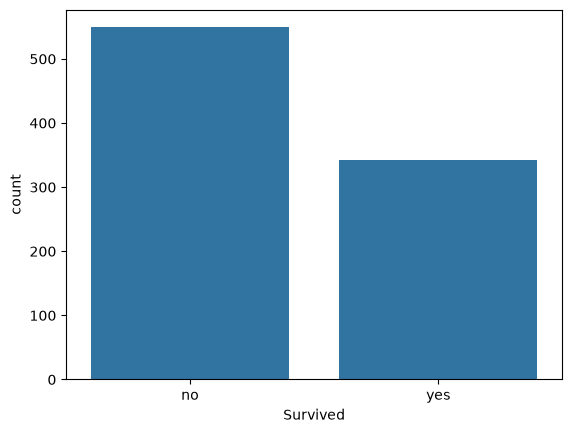

In [50]:
countplot = sns.countplot(data=df, x='Survived')

plt.show()

[<BarContainer object of 2 artists>]


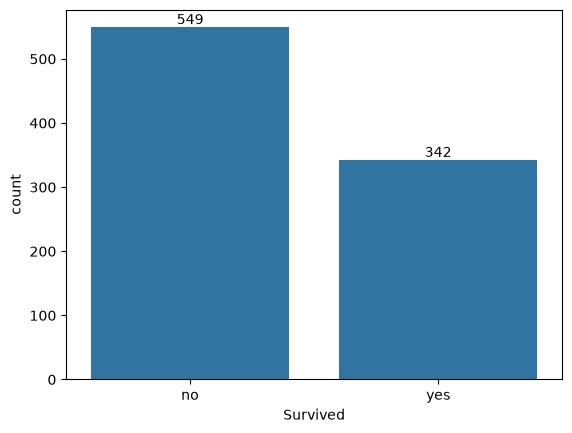

In [ ]:
# add count on top of a bar
countplot = sns.countplot(data=df, x='Survived')
countplot.bar_label(countplot.containers[0])
plt.show()

In [ ]:
# percentage of people who survived

df['Survived'].value_counts(normalize=True)

Survived
no     0.616162
yes    0.383838
Name: proportion, dtype: float64

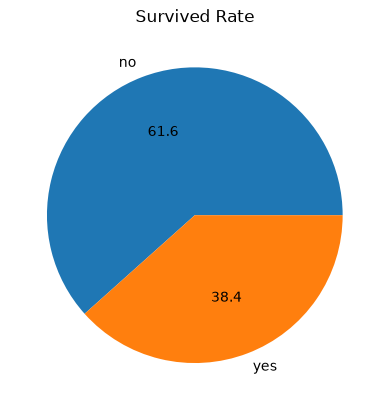

In [59]:
# pie chart of survived people

survived_count = df['Survived'].value_counts()

plt.pie(survived_count, autopct='%1.1f', labels=['no', 'yes'])
plt.title('Survived Rate')
plt.show()

[Text(0, 0, '491'), Text(0, 0, '216'), Text(0, 0, '184')]

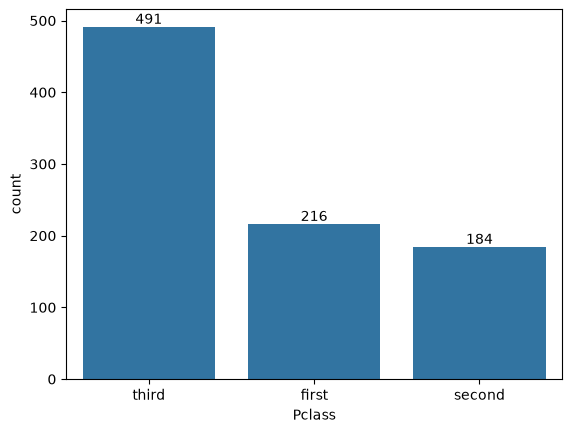

In [66]:
# countplot of Pclass

pclass_count = sns.countplot(
    data=df,
    x='Pclass'
)

pclass_count.bar_label(pclass_count.containers[0])

#### Age Histogram and KDE Plot

Text(0, 0.5, 'Frequency')

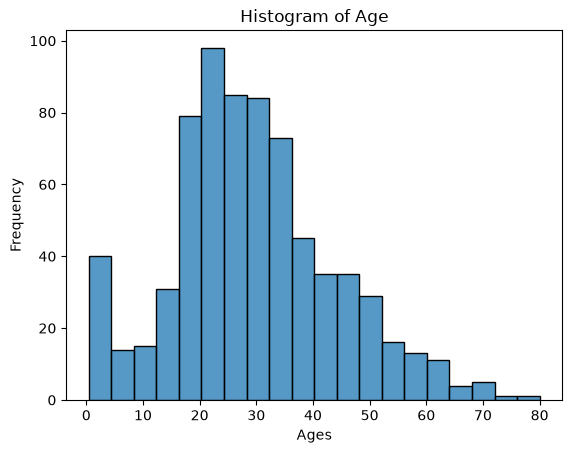

In [12]:
sns.histplot(df['Age'], bins=20)

plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('Frequency')

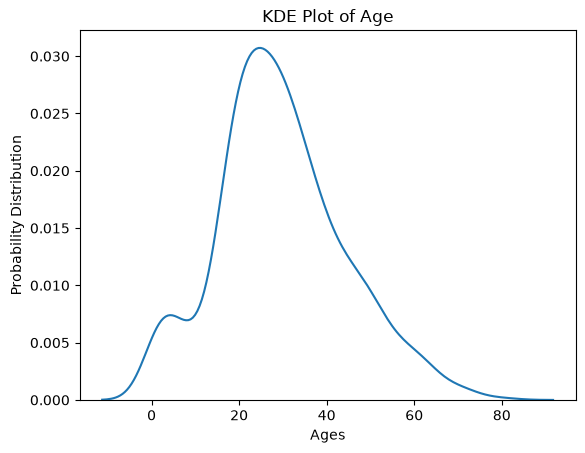

In [11]:
sns.kdeplot(df['Age'])

plt.title('KDE Plot of Age')
plt.xlabel('Ages')
plt.ylabel('Probability Distribution')
plt.show()

#### Fare Histogram and KDE Plot

<Axes: xlabel='Fare', ylabel='Count'>

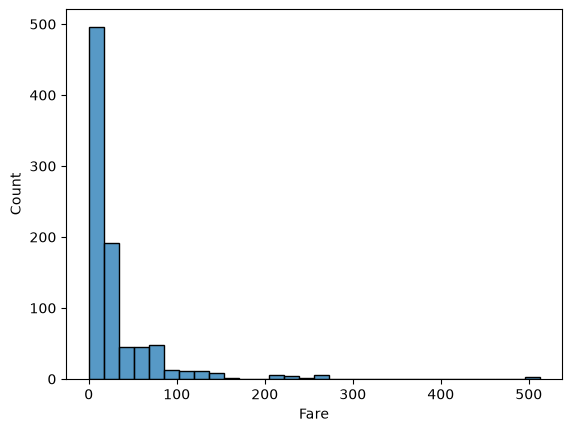

In [17]:
sns.histplot(df['Fare'], bins=30)

<Axes: xlabel='Fare', ylabel='Density'>

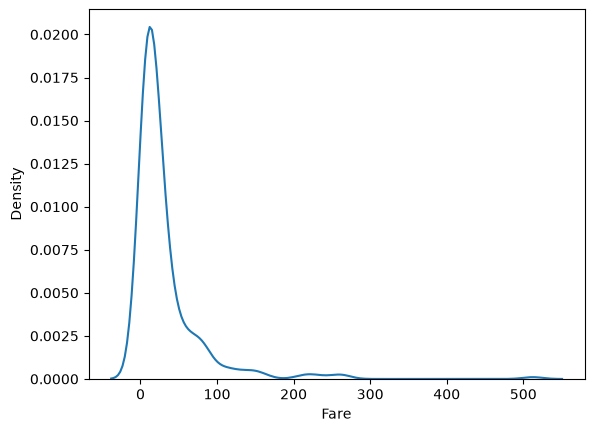

In [18]:
sns.kdeplot(df['Fare'])